### LangGraph核心组件：人机交互

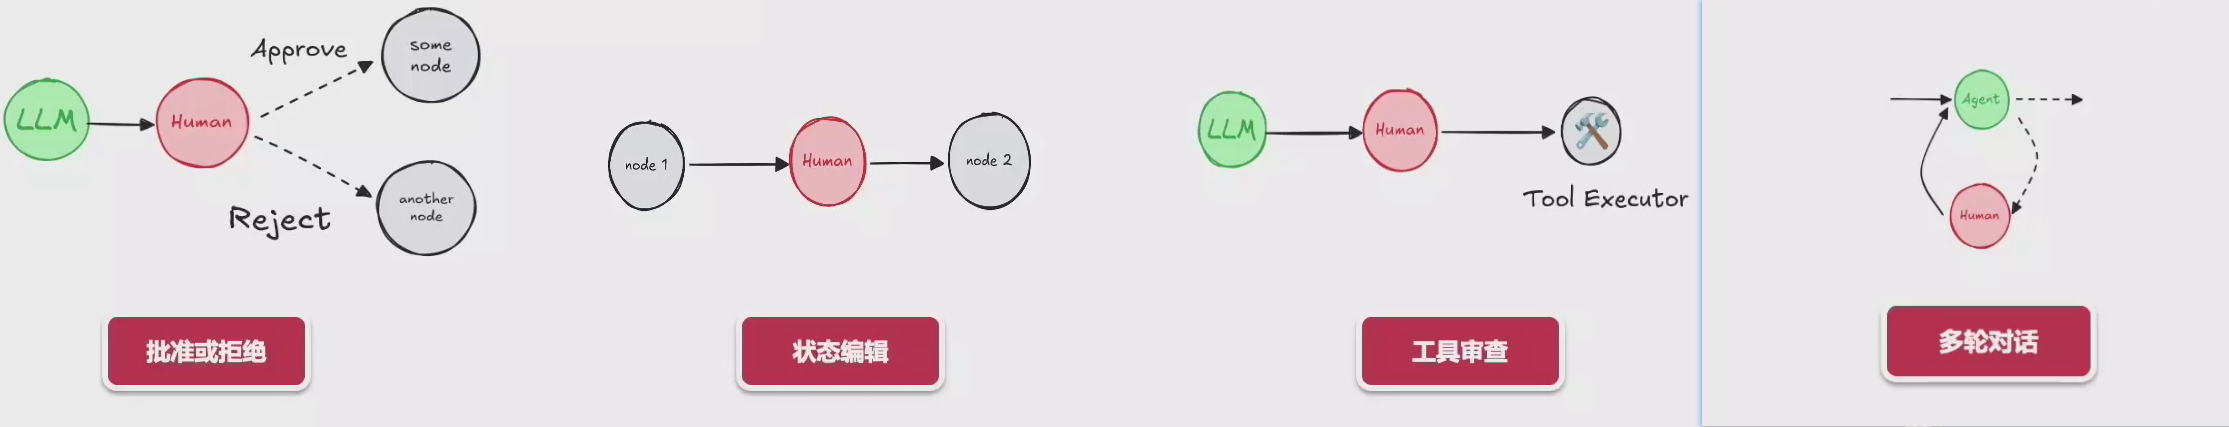

- 审查工具调用情况（是否正确等）
- 审查和验证LLM输出
- 人工提供更好更多的上下文背景



#### 审查工具调用
***
人工介入智能体的工具调用过程，实现人机协同

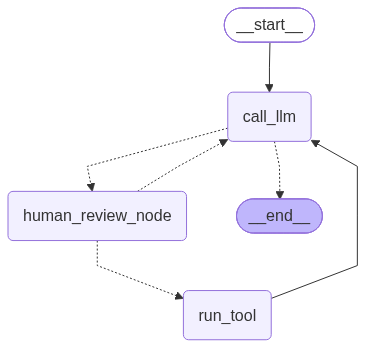

In [2]:
from typing_extensions import TypedDict, Literal
from langgraph.graph import StateGraph, START, END, MessagesState
from langgraph.checkpoint.memory import MemorySaver
from langgraph.types import Command, interrupt
from langchain_core.tools import tool
from langchain_core.messages import AIMessage
from IPython.display import Image, display

@tool
def weather_search(city: str):
    """搜索天气"""
    print("-----")
    print(f"正在搜索：{city}")
    print("-----")
    return "晴朗"

# 设置模型
from langchain_deepseek import ChatDeepSeek
import os
from dotenv import load_dotenv
load_dotenv()

deepseek = ChatDeepSeek(
    model = "deepseek-ai/DeepSeek-V4-Flash",
    temperature=0,
    api_key=os.getenv("ds_api_key"),
    base_url=os.getenv("ds_base_url")
)

model = deepseek.bind_tools(
    [weather_search]
)

class State(MessagesState):
    """简单状态。"""

def call_llm(state):
    return {"messages": [model.invoke(state["messages"])]}

def human_review_node(state) -> Command[Literal["call_llm", "run_tool"]]:
    last_message = state["messages"][-1]
    tool_call = last_message.tool_calls[-1]

    # 将通过Command(resume=<human_review>)提供的值
    human_review = interrupt({
        "question": "这是正确的么？",
        # 显示工具调用以提供审核
        "tool_call": tool_call,
    })

    review_action = human_review["action"]
    review_data = human_review.get("data")

    # 如果批准，调用工具
    if review_action == "continue":
        return Command(goto="run_tool")
    # 更新AI消息并调用工具
    elif review_action == "update":
        updated_message = {
            "role": "ai",
            "content": last_message.content,
            "tool_calls": [{
                "id": tool_call["id"],
                "name": tool_call["name"],
                # 这是人类提供的更新
                "args":review_data,
            }],
            # 这很重要- 这需要与你替换的消息相同!
            # 否则，它将显示为一个单独的消息
            "id": last_message.id,
        }
        return Command(goto="run_tool", update={"messages": [updated_message]})
    # 向LLM提供反馈
    elif review_action == "feedback":
        # #注意：将反馈消息添加为ToolMessage
        # 以保持消息历史中的正确顺序 (带有工具调用的AI消息需要后跟工具调用消息)
        tool_message = {
            "role": "tool",
            "name": tool_call["name"],
            "content": review_data,
            "tool_call_id": tool_call["id"],
        }
        return Command(goto="call_llm", update={"messages": [tool_message]})

def run_tool(state):
    new_messages = []
    tools = {"weather_search": weather_search}
    tool_calls = state["messages"][-1].tool_calls
    for tool_call in tool_calls:
        tool = tools[tool_call["name"]]
        result = tool.invoke(tool_call["args"])
        new_messages.append({
            "role": "tool",
            "name": tool_call["name"],
            "content": result,
            "tool_call_id": tool_call["id"],
        })
    return {"messages": new_messages}

def route_after_llm(state) -> Literal[END, "human_review_node"]:
    if len(state["messages"][-1].tool_calls) == 0:
        return END
    else:
        return "human_review_node"

builder = StateGraph(State)
builder.add_node(call_llm)
builder.add_node(run_tool)
builder.add_node(human_review_node)
builder.add_edge(START, "call_llm")
builder.add_conditional_edges("call_llm", route_after_llm)
builder.add_edge("run_tool", "call_llm")

# 设置内存
memory = MemorySaver()

# 添加
graph = builder.compile(checkpointer=memory)

# 查看
display(Image(graph.get_graph().draw_mermaid_png()))


当不涉及工具调用的时候，不会触发人工审核

In [4]:
# input
initial_input = {"messages": [{"role": "human", "content": "你好"}]}

thread = {"configurable": {"thread_id": "1"}}

for event in graph.stream(initial_input, thread, stream_mode="updates"):
    print(event)
    print("\n")

{'call_llm': {'messages': [AIMessage(content='你好！很高兴见到你。有什么我可以帮你的吗？', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 12, 'prompt_tokens': 295, 'total_tokens': 307, 'completion_tokens_details': {'accepted_prediction_tokens': None, 'audio_tokens': None, 'reasoning_tokens': 0, 'rejected_prediction_tokens': None}, 'prompt_tokens_details': {'audio_tokens': None, 'cache_write_tokens': None, 'cached_tokens': 0}, 'prompt_cache_hit_tokens': 0, 'prompt_cache_miss_tokens': 295}, 'model_provider': 'deepseek', 'model_name': 'deepseek-ai/DeepSeek-V4-Flash', 'system_fingerprint': '', 'id': '01a17c871bedf9dd82ce4480822796ef', 'finish_reason': 'stop', 'logprobs': None}, id='lc_run--01a17c87-06d0-76d1-a00c-3a1b4bd07f38-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 295, 'output_tokens': 12, 'total_tokens': 307, 'input_token_details': {'cache_read': 0}, 'output_token_details': {'reasoning': 0}})]}}




一旦涉及到工具调用就会触发人工介入

In [5]:
# input
initial_input = {"messages": [{"role": "human", "content": "北京的天气怎么样？"}]}

thread = {"configurable": {"thread_id": "1"}}

for event in graph.stream(initial_input, thread, stream_mode="updates"):
    print(event)
    print("\n")

{'call_llm': {'messages': [AIMessage(content='\n\n我来帮你查询一下北京的天气情况。', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 51, 'prompt_tokens': 315, 'total_tokens': 366, 'completion_tokens_details': {'accepted_prediction_tokens': None, 'audio_tokens': None, 'reasoning_tokens': 0, 'rejected_prediction_tokens': None}, 'prompt_tokens_details': {'audio_tokens': None, 'cache_write_tokens': None, 'cached_tokens': 0}, 'prompt_cache_hit_tokens': 0, 'prompt_cache_miss_tokens': 315}, 'model_provider': 'deepseek', 'model_name': 'deepseek-ai/DeepSeek-V4-Flash', 'system_fingerprint': '', 'id': '01a17c8744e12183c73bf29f788bfb3a', 'finish_reason': 'tool_calls', 'logprobs': None}, id='lc_run--01a17c87-3019-7e23-af00-3617c1f5c673-0', tool_calls=[{'name': 'weather_search', 'args': {'city': '北京'}, 'id': '01a17c8760e950fb0e19af4ba8d958d2', 'type': 'tool_call'}], invalid_tool_calls=[], usage_metadata={'input_tokens': 315, 'output_tokens': 51, 'total_tokens': 366, 'inp

使用Command进行人机交互

In [6]:
for event in graph.stream(
    # 输入值
    Command(resume={"action": "continue"}),
    thread,
    stream_mode="updates"
):
    print(event)
    print("\n")

{'human_review_node': None}


-----
正在搜索：北京
-----
{'run_tool': {'messages': [{'role': 'tool', 'name': 'weather_search', 'content': '晴朗', 'tool_call_id': '01a17c8760e950fb0e19af4ba8d958d2'}]}}


{'call_llm': {'messages': [AIMessage(content='北京今天的天气是**晴朗**的！☀️\n\n天气不错，适合外出活动。如果你需要更详细的天气信息（比如温度、风力等），或者想了解其他城市的天气，随时告诉我哦！', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 44, 'prompt_tokens': 384, 'total_tokens': 428, 'completion_tokens_details': {'accepted_prediction_tokens': None, 'audio_tokens': None, 'reasoning_tokens': 0, 'rejected_prediction_tokens': None}, 'prompt_tokens_details': {'audio_tokens': None, 'cache_write_tokens': None, 'cached_tokens': 0}, 'prompt_cache_hit_tokens': 0, 'prompt_cache_miss_tokens': 384}, 'model_provider': 'deepseek', 'model_name': 'deepseek-ai/DeepSeek-V4-Flash', 'system_fingerprint': '', 'id': '01a17c876da3637aa2199ce7288f3f0e', 'finish_reason': 'stop', 'logprobs': None}, id='lc_run--01a17c87-58e2-7c80-8ba9-82dfa

更进一步，对智能体调用的工具进行参数编辑

In [7]:
# input
initial_input = {"messages": [{"role": "human", "content": "深圳的天气怎么样？"}]}

thread = {"configurable": {"thread_id": "1"}}

for event in graph.stream(initial_input, thread, stream_mode="updates"):
    print(event)
    print("\n")

{'call_llm': {'messages': [AIMessage(content='\n\n我来帮你查询一下深圳的天气情况。', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 52, 'prompt_tokens': 437, 'total_tokens': 489, 'completion_tokens_details': {'accepted_prediction_tokens': None, 'audio_tokens': None, 'reasoning_tokens': 0, 'rejected_prediction_tokens': None}, 'prompt_tokens_details': {'audio_tokens': None, 'cache_write_tokens': None, 'cached_tokens': 0}, 'prompt_cache_hit_tokens': 0, 'prompt_cache_miss_tokens': 437}, 'model_provider': 'deepseek', 'model_name': 'deepseek-ai/DeepSeek-V4-Flash', 'system_fingerprint': '', 'id': '01a17c877e42ee5988bba67f2635542d', 'finish_reason': 'tool_calls', 'logprobs': None}, id='lc_run--01a17c87-6979-7c42-8a04-5fde52ab09d1-0', tool_calls=[{'name': 'weather_search', 'args': {'city': '深圳'}, 'id': '01a17c8783b78eea39843f56b9e60a9f', 'type': 'tool_call'}], invalid_tool_calls=[], usage_metadata={'input_tokens': 437, 'output_tokens': 52, 'total_tokens': 489, 'inp

In [8]:
# 直接对工具的参数进行编辑
for event in graph.stream(
    Command(resume={"action": "update", "data": {"city": "上海,中国"}}),
    thread,
    stream_mode="updates"
):
    print(event)
    print("\n")

{'human_review_node': {'messages': [{'role': 'ai', 'content': '\n\n我来帮你查询一下深圳的天气情况。', 'tool_calls': [{'id': '01a17c8783b78eea39843f56b9e60a9f', 'name': 'weather_search', 'args': {'city': '上海,中国'}}], 'id': 'lc_run--01a17c87-6979-7c42-8a04-5fde52ab09d1-0'}]}}


-----
正在搜索：上海,中国
-----
{'run_tool': {'messages': [{'role': 'tool', 'name': 'weather_search', 'content': '晴朗', 'tool_call_id': '01a17c8783b78eea39843f56b9e60a9f'}]}}


{'call_llm': {'messages': [AIMessage(content='抱歉，我刚才查询错了城市。让我重新查询一下深圳的天气。', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 57, 'prompt_tokens': 509, 'total_tokens': 566, 'completion_tokens_details': {'accepted_prediction_tokens': None, 'audio_tokens': None, 'reasoning_tokens': 0, 'rejected_prediction_tokens': None}, 'prompt_tokens_details': {'audio_tokens': None, 'cache_write_tokens': None, 'cached_tokens': 0}, 'prompt_cache_hit_tokens': 0, 'prompt_cache_miss_tokens': 509}, 'model_provider': 'deepseek', 'model_name': 'dee

#### 人机交互 - 对图状态进行编辑
***
使用断点对节点间的消息进行人工干预

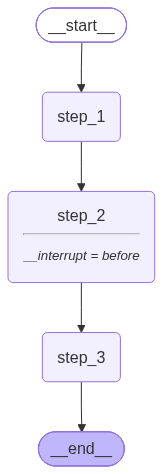

In [9]:
from typing_extensions import TypedDict
from langgraph.graph import StateGraph, START, END
from langgraph.checkpoint.memory import MemorySaver
from IPython.display import Image, display

class State(TypedDict):
    input: str

def step_1(state):
    print("Step 1: Received input:", state["input"])
    pass

def step_2(state):
    print("Step 2: Processing input:", state["input"])
    pass

def step_3(state):
    print("Step 3: Finalizing input:", state["input"])
    pass

builder = StateGraph(State)
builder.add_node("step_1", step_1)
builder.add_node("step_2", step_2)
builder.add_node("step_3", step_3)
builder.add_edge(START, "step_1")
builder.add_edge("step_1", "step_2")
builder.add_edge("step_2", "step_3")
builder.add_edge("step_3", END)

# 设置内存
memory = MemorySaver()  

# 编译图形并设置中断点 注意 interrupt_before
graph = builder.compile(checkpointer=memory, interrupt_before=["step_2"])

# 查看图形
display(Image(graph.get_graph().draw_mermaid_png()))

In [10]:
# input 
initial_input = {"input": "你好！"}

# thread
thread = {"configurable": {"thread_id": "1"}}

# Run the graph with the initial input and thread
for event in graph.stream(initial_input, thread, stream_mode="values"):
    print(event)

{'input': '你好！'}
Step 1: Received input: 你好！


此时可以人工介入

In [11]:
graph.update_state(thread, {"input": "你好！ 1goto.ai!"})
print("-----\n-----Update state!-----\n-----")
print(graph.get_state(thread).values)

-----
-----Update state!-----
-----
{'input': '你好！ 1goto.ai!'}


In [12]:
# 继续执行
for event in graph.stream(None, thread, stream_mode="values"):
    print(event)    

{'input': '你好！ 1goto.ai!'}
Step 2: Processing input: 你好！ 1goto.ai!
Step 3: Finalizing input: 你好！ 1goto.ai!
